# A04 · 03 · Differential expression (pydeseq2)
Design `~ group` (Mock_0…Cd_10), single donor → no donor/batch term.
Contrasts: Cd-vs-Mock at each dose; butyrate within each arm.

In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))   # a04_common.py next to notebooks
import a04_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('project root:', ac.PROJ)
ac # needs: pip install pydeseq2

In [ ]:
counts = ac.load_counts(); meta = ac.load_meta(); counts = counts[meta.index]
id2sym, sym2id = ac.load_symbol_map()
counts_f = ac.prefilter(counts)
dds = ac.build_dds(counts_f, meta)
print('dds fitted on', counts_f.shape[0], 'genes')

## Run all contrasts, save tables, volcanoes

In [3]:
results = {}
for name, con in ac.CONTRASTS.items():
    r = ac.run_contrast(dds, con, id2sym); results[name] = r
    r.to_csv(ac.TAB/f'DE_{name}.csv')
    nsig = (r['padj']<0.05).sum(); print(f'{name:22s} {nsig:5d} genes padj<0.05')

Cd_vs_Mock_0mM          7605 genes padj<0.05
Cd_vs_Mock_5mM          7918 genes padj<0.05
Cd_vs_Mock_10mM         7540 genes padj<0.05
Butyrate_10v0_Mock      4948 genes padj<0.05
Butyrate_5v0_Mock        264 genes padj<0.05
Butyrate_10v0_Cd        4123 genes padj<0.05
Butyrate_5v0_Cd         1328 genes padj<0.05


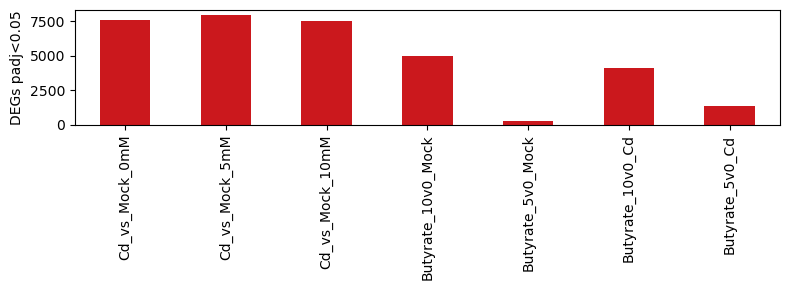

In [4]:
# DEG count summary
deg = {k:(v['padj']<0.05).sum() for k,v in results.items()}
ax = pd.Series(deg).plot.bar(figsize=(8,3), color='#cb181d'); ax.set_ylabel('DEGs padj<0.05')
plt.tight_layout(); plt.show()

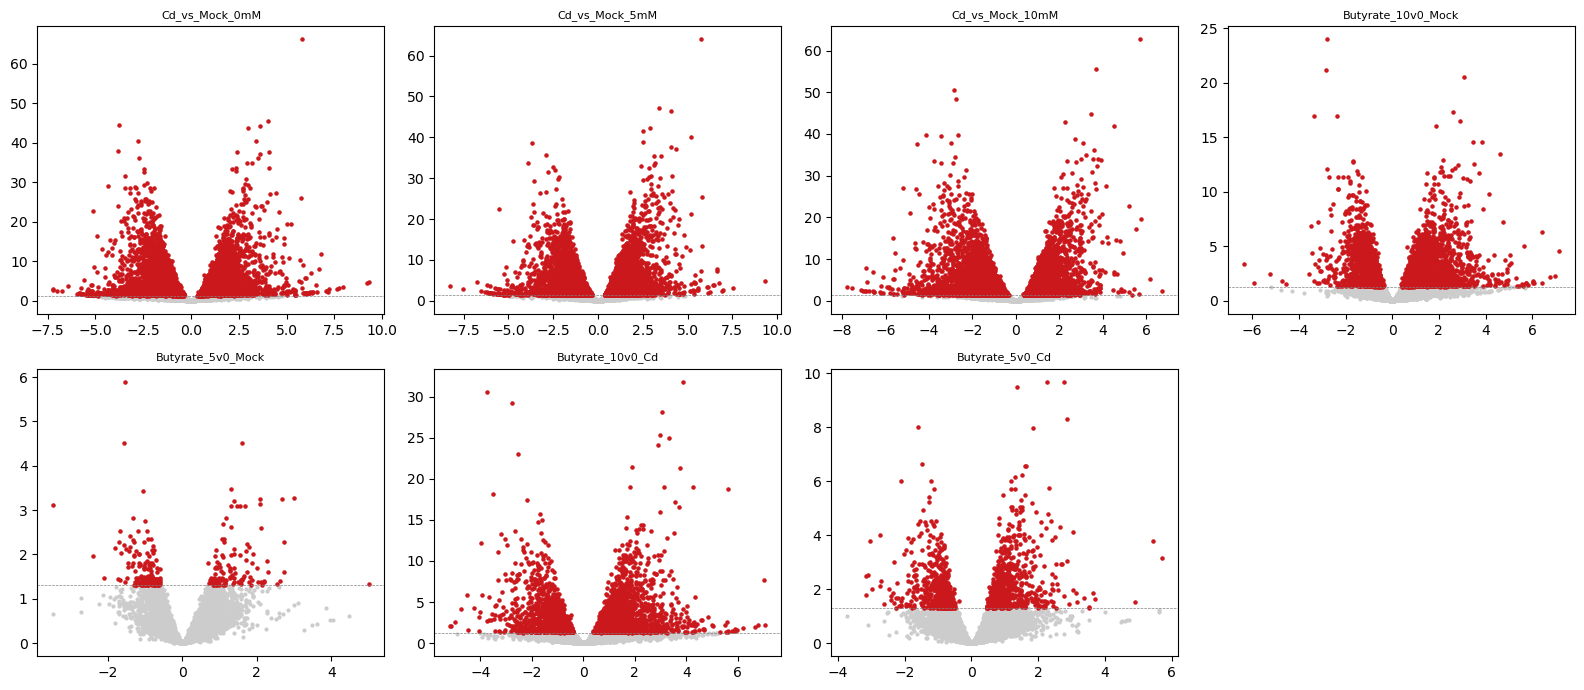

In [5]:
# volcanoes
fig, axes = plt.subplots(2, 4, figsize=(16,7)); axes = axes.ravel()
for ax,(name,r) in zip(axes, results.items()):
    x=r['log2FoldChange']; y=-np.log10(r['padj'].clip(lower=1e-300)); sig=r['padj']<0.05
    ax.scatter(x[~sig],y[~sig],s=4,c='#cccccc'); ax.scatter(x[sig],y[sig],s=5,c='#cb181d')
    ax.axhline(-np.log10(0.05),ls='--',c='grey',lw=.5); ax.set_title(name,fontsize=8)
for ax in axes[len(results):]: ax.axis('off')
plt.tight_layout(); plt.show()

In [6]:
# top genes for the primary contrast
results['Cd_vs_Mock_0mM'].head(20)[['symbol','log2FoldChange','padj']]

,symbol,log2FoldChange,padj
ENSG00000115009,CCL20,5.831417,6.478135e-67
ENSG00000189325,BNIP5,4.028041,2.901375e-46
ENSG00000291029,FKBP9P1,-3.750621,2.854313e-45
ENSG00000144802,NFKBIZ,3.628374,6.167399e-45
ENSG00000141452,RMC1,2.978482,2.330253e-44
ENSG00000016402,IL20RA,-2.783023,3.499356e-41
ENSG00000118503,TNFAIP3,3.412166,4.275383e-41
ENSG00000219607,PPP1R3G,-3.834224,1.565447e-38
ENSG00000169429,CXCL8,4.089607,1.644654e-38
ENSG00000130956,HABP4,2.384979,2.824560e-38
